# Guía L2 — El índice sancocho · **Sesión 1: la receta como función**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

> Esta idea nació un domingo en Berlín, entre un döner y el recuerdo de una bullabesa. La historia completa está en la guía: este cuaderno es la sobremesa vuelta código.

**Uso en Colab:** guarden su copia (`Archivo → Guardar una copia en Drive`) y renómbrenla `L2_apellidos.ipynb`. Las celdas marcadas con ✏️ invitan a explorar o modificar; las marcadas con 🗣️ son para escribir conclusiones del equipo.

---
## ⏸️ Momento 1 — Predecir

Antes de ejecutar, respondan P1, P2 y P3 de la guía en papel: el costo del sancocho para seis en Manizales, si manda el espinazo o el resto de la olla, y si subió más la papa o el plátano. Foto al informe.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Precios mayoristas mensuales de SIPSA-DANE, congelados por el curso.
# El archivo .csv.gz se lee directamente: pandas reconoce la compresión.
RUTA = (
    "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/"
    "main/datos/sipsa_mensual.csv.gz"
)
df = pd.read_csv(RUTA)

print("Filas y columnas:", df.shape)
df.head(8)

Filas y columnas: (666865, 5)


,fecha,ciudad,mercado,producto,precio_kg
0,2013-01,Armenia,"Armenia, Frigocafé",Carne de cerdo en canal,6320.0
1,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, brazo con hueso",8520.0
2,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, brazo sin hueso",9000.0
3,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, cabeza de lomo",9020.0
4,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, costilla",9020.0
5,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, espinazo",6520.0
6,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, lomo con hueso",11020.0
7,2013-01,Armenia,"Armenia, Frigocafé","Carne de cerdo, lomo sin hueso",12020.0


---
## 1 · El ritual, ya sin niñera

En L1 lo hicimos juntos; hoy es de ustedes. El objetivo es decidir qué valores acepta cada columna, buscar valores ilegales y entender el alcance del congelado. Después, busquen los nombres oficiales de los ingredientes: los datos no saben cómo los llamamos en la casa.

🗣️ Escriban como comentario sus decisiones sobre los valores faltantes, precios no positivos y filas repetidas. ¿Una fila por `(fecha, mercado, producto)` es lo esperado?

In [ ]:
# ✏️ Ejercicio 1 — Completen la auditoría y dejen sus decisiones en comentarios.
print("Productos distintos:", df["producto"].nunique())
print("Ciudades:", df["ciudad"].nunique())
print("Meses: de", df["fecha"].min(), "a", df["fecha"].max())
print("\nTipos de dato:\n", df.dtypes)
print("\nValores faltantes por columna:\n", df.isna().sum())
print("\nPrecios medios no positivos:", (df["precio_kg"] <= 0).sum())
print("Filas repetidas por fecha, mercado y producto:",
      df.duplicated(["fecha", "mercado", "producto"]).sum())

# ¿Qué dominio matemático le asignan a fecha, ciudad, mercado, producto y precio_kg?
 # R: fecha -> meses AAAA-MM de 2013-01 a 2024-12 (conjunto discreto y ordenado de 144 meses);
 #    ciudad -> conjunto finito de 71 ciudades; mercado -> conjunto finito de centrales de abastos;
 #    producto -> conjunto finito de 385 nombres oficiales (texto, sin orden);
 #    precio_kg -> numeros reales positivos (0, +inf), en pesos por kilogramo.
 #
 # Decisiones de la auditoria:
 # - Valores faltantes: hay 0 en todas las columnas, asi que no se borra ni se rellena nada.
 #   Si aparecieran, no los rellenariamos con 0 (seria un precio ilegal); los dejariamos fuera del calculo.
 # - Precios no positivos: hay 0. Un precio <= 0 no tiene sentido fisico, se trataria como error y se quitaria.
 # - Filas repetidas por (fecha, mercado, producto): hay 0, entonces cada combinacion tiene un unico precio.
 #   Si, una fila por (fecha, mercado, producto) es lo esperado: SIPSA reporta un precio medio mensual
 #   por producto en cada mercado. Por (fecha, ciudad, producto) SI puede haber varias filas, porque
 #   algunas ciudades tienen varias centrales; por eso costear() usa mean.
 # - Alcance del congelado: precios mayoristas mensuales de SIPSA-DANE, de enero de 2013 a diciembre
 #   de 2024; no hay datos posteriores ni precios de tienda.

Productos distintos: 385
Ciudades: 71
Meses: de 2013-01 a 2024-12

Tipos de dato:
 fecha         object
ciudad        object
mercado       object
producto      object
precio_kg    float64
dtype: object

Valores faltantes por columna:
 fecha        0
ciudad       0
mercado      0
producto     0
precio_kg    0
dtype: int64

Precios medios no positivos: 0
Filas repetidas por fecha, mercado y producto: 0


In [ ]:
# ✏️ Ejercicio 2 — Cambien `busca` e iteren.
# Encuentren los nombres oficiales de espinazo, yuca, papa, mazorca y plátano verde.
for busca in ["espinazo", "yuca", "papa", "mazorca", "plátano"]:
    nombres = df.loc[df["producto"].str.contains(busca, case=False, na=False), "producto"].unique()
    print(f"País · {busca}: {len(nombres)} nombres")
# Luego restrinjan la búsqueda a Manizales: no todas las variedades se venden allí.
busca = "espinazo"
coincidencias = df.loc[
    df["producto"].str.contains(busca, case=False, na=False),
    ["ciudad", "mercado", "producto"],
]
print(coincidencias["producto"].drop_duplicates().to_list())

# Pista para Manizales:
# df.loc[(df["ciudad"] == "Manizales") &
#        df["producto"].str.contains(busca, case=False, na=False), "producto"].unique()

País · espinazo: 1 nombres
País · yuca: 4 nombres
País · papa: 29 nombres
País · mazorca: 1 nombres
País · plátano: 11 nombres
['Carne de cerdo, espinazo']


---
## 2 · La receta en código

La receta oficial es para seis personas. Cada valor está en kilogramos, que es la unidad del mercado: 1,5 kg de espinazo, 1 kg de yuca, 1 kg de papa, 0,9 kg de mazorca y 1,4 kg de plátano. Traducir de unidades de cocina a kilogramos también es una función.

In [ ]:
RECETA = {
    "Carne de cerdo, espinazo":       1.5,
    "Yuca ICA":                       1.0,
    "Papa capira":                    1.0,
    "Chócolo mazorca":                0.9,
    "Plátano dominico hartón verde":  1.4,
}
print("Ingredientes:", len(RECETA), "| Kilos totales:", sum(RECETA.values()))

# ✏️ Confirmen que cada nombre existe para Manizales antes de seguir.
mzl = df[df["ciudad"] == "Manizales"]
for producto in RECETA:
    meses = mzl.loc[mzl["producto"] == producto, "fecha"].nunique()
    marca = "si esta" if meses == 144 else "⚠️ incompleto"
    print(f"{producto}: {meses} de 144 meses {marca}")

Ingredientes: 5 | Kilos totales: 5.8
Carne de cerdo, espinazo: 144 de 144 meses si esta
Yuca ICA: 144 de 144 meses si esta
Papa capira: 144 de 144 meses si esta
Chócolo mazorca: 144 de 144 meses si esta
Plátano dominico hartón verde: 144 de 144 meses si esta


---
## 3 · El pipeline, pieza por pieza

Estas cuatro funciones son puras: reciben una tabla y sus parámetros, y devuelven una tabla o un número. No dependen de `df`, `RECETA` ni ninguna otra variable externa. Lean cada contrato, prueben cada función por separado y luego sigan el dato a través de la composición.

In [ ]:
def filtrar_ciudad(tabla, ciudad):
    """tabla → tabla: conserva únicamente las filas de una ciudad."""
    return tabla.loc[tabla["ciudad"] == ciudad].copy()

def filtrar_mes(tabla, fecha):
    """tabla → tabla: conserva únicamente el mes AAAA-MM indicado."""
    return tabla.loc[tabla["fecha"] == fecha].copy()

def filtrar_productos(tabla, receta):
    """tabla → tabla: conserva los productos que aparecen en la receta."""
    return tabla.loc[tabla["producto"].isin(receta)].copy()

def costear(tabla, receta):
    """tabla → número: suma kilos × precio_kg de cada ingrediente."""
    precios = tabla.groupby("producto")["precio_kg"].mean()
    faltantes = [producto for producto in receta if producto not in precios]
    if faltantes:
        raise ValueError(f"Faltan ingredientes: {faltantes}")
    return sum(kilos * precios[producto] for producto, kilos in receta.items())

# ✏️ ¿Por qué `.isin(receta)` sirve para varios productos y `== receta` no?
# ¿En qué situación habría varias filas del mismo ingrediente y por qué usamos `mean`?

In [ ]:
# Prueba de cada función por separado
paso1 = filtrar_ciudad(df, "Manizales")
print("1) filtrar_ciudad →", paso1.shape, "| ciudades:", paso1["ciudad"].unique())

ultimo_mes = paso1["fecha"].max()
paso2 = filtrar_mes(paso1, ultimo_mes)
print("2) filtrar_mes →", paso2.shape, "| mes:", paso2["fecha"].unique())

paso3 = filtrar_productos(paso2, RECETA)
print("3) filtrar_productos →", paso3.shape)
print(paso3[["mercado", "producto", "precio_kg"]])

paso4 = costear(paso3, RECETA)
print(f"4) costear → ${paso4:,.0f}")

1) filtrar_ciudad → (16936, 5) | ciudades: ['Manizales']
2) filtrar_mes → (111, 5) | mes: ['2024-12']
3) filtrar_productos → (5, 5)
                           mercado                       producto  precio_kg
664619  Manizales, Centro Galerías       Carne de cerdo, espinazo    13500.0
664641  Manizales, Centro Galerías                Chócolo mazorca     1273.0
664683  Manizales, Centro Galerías                    Papa capira     2133.0
664696  Manizales, Centro Galerías  Plátano dominico hartón verde     2663.0
664711  Manizales, Centro Galerías                       Yuca ICA     1377.0
4) costear → $28,634


#¿Por qué `.isin(receta)` sirve para varios productos y `== receta` no?
# R: (compara cada producto con UN solo valor, y un nombre como "Papa capira" nunca es
#    igual al diccionario RECETA completo. `.isin(receta)` pregunta si el producto ESTÁ DENTRO
#    de la colección (las claves de RECETA), así que deja pasar los 5 ingredientes a la vez.
)
# ¿En qué situación habría varias filas del mismo ingrediente y por qué usamos `mean`?
# R: ( Cuando la ciudad tiene varias centrales de abastos (por ejemplo Bogotá o Medellín), cada
#    mercado reporta su propio precio del mismo producto en el mismo mes. `mean` los resume en
#    un solo precio por ingrediente (promedio simple, decisión de modelación de la guía). En
#    Manizales no pasa: hay una sola central (Centro Galerías), por eso salieron solo 5 filas.)

In [ ]:
# Una función que fabrica la función compuesta.
def componer(*funciones):
    def compuesta(x):
        for funcion in funciones:
            x = funcion(x)
        return x
    return compuesta

CIUDAD = "Manizales"
MES = df.loc[df["ciudad"] == CIUDAD, "fecha"].max()

costo_sancocho = componer(
    lambda tabla: filtrar_ciudad(tabla, CIUDAD),
    lambda tabla: filtrar_mes(tabla, MES),
    lambda tabla: filtrar_productos(tabla, RECETA),
    lambda tabla: costear(tabla, RECETA),
)

print(f"Mercado del sancocho en {CIUDAD}, {MES}: ${costo_sancocho(df):,.0f}")

# ✏️ Dibujen el recorrido de `df` por las cuatro funciones.
# R:  df (666.865 filas, todo el país)
#      │ filtrar_ciudad(·, "Manizales")
#      ▼
#     16.936 filas (solo Manizales)
#      │ filtrar_mes(·, "2024-12")
#      ▼
#     111 filas (solo diciembre de 2024)
#      │ filtrar_productos(·, RECETA)
#      ▼
#     5 filas (un precio por ingrediente)
#      │ costear(·, RECETA)
#      ▼
#     $28.634 (un número: el costo del sancocho)
#    Tres funciones van de tabla → tabla y la última de tabla → número.

# ¿Por qué una lambda permite fijar ciudad, mes y receta sin romper la pureza de las funciones?
# R: componer() necesita funciones de UN solo argumento (la tabla), pero las nuestras reciben dos
#    (la tabla y un parámetro). La lambda las "envuelve": fija el segundo argumento
#    (CIUDAD, MES o RECETA) y deja una función que solo recibe la tabla. Las cuatro funciones
#    originales no cambian: siguen recibiendo todo por parámetro y sin tocar variables externas,
#    así que siguen siendo puras. Lo que depende de CIUDAD, MES y RECETA es la lambda, no ellas.

Mercado del sancocho en Manizales, 2024-12: $28,634


🗣️ **Confronten P1:** ¿quién tuvo el mejor ojo de mercado? Los datos son precios mayoristas de una central de abastos: ¿el mercado de la esquina cobraría más o menos y por qué?

**Respuesta del equipo:** Apostamos \$62.062, que defendió Sebastián Gutiérrez, y el costo real en Manizales en diciembre de 2024 fue \$28.634: nos pasamos unas 2,2 veces. Nuestra apuesta fue para un sancocho de 4 o 5 personas, así que redujimos la yuca, la papa, la mazorca y el plátano, pero mantuvimos 1,5 kg de espinazo. Aun con menos ingredientes, nuestro número salió más del doble del real, que es para seis personas, así que el error está en los precios y no en las cantidades. Casi toda la diferencia está en el espinazo: lo estimamos en \$36.000/kg y el precio mayorista era \$13.500/kg, lo que solo en ese ingrediente suma \$33.750. En papa (\$2.000 contra \$2.133) y yuca (\$2.000 contra \$1.377) estuvimos cerca, y la mazorca la sobreestimamos (\$6.000 contra \$1.273).

El mercado de la esquina cobraría **más** que \$28.634, porque los datos del DANE son precios mayoristas de la central de abastos: la tienda le suma el transporte, el almacenamiento y su ganancia. Nuestra predicción se acercó más a un precio de tienda o de carnicería que a uno mayorista.

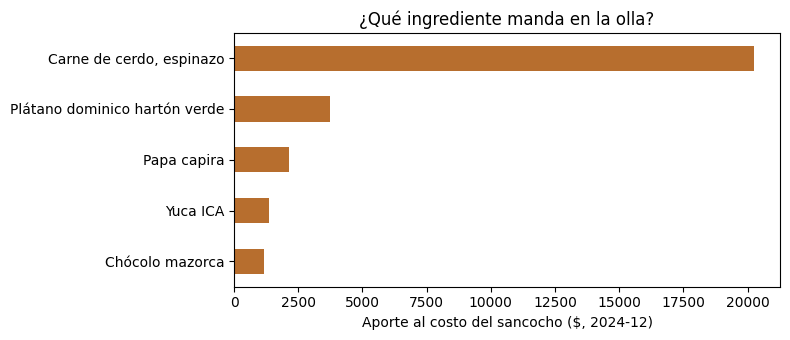

El espinazo aporta $20,250 de $28,634: 71% de la olla.


In [ ]:
# ¿Qué ingrediente manda? Confronten P2 con los aportes al costo.
mes_tabla = filtrar_productos(
    filtrar_mes(filtrar_ciudad(df, CIUDAD), MES), RECETA
)
precios_mes = mes_tabla.groupby("producto")["precio_kg"].mean()
aportes = pd.Series({
    producto: kilos * precios_mes[producto]
    for producto, kilos in RECETA.items()
}).sort_values()

ax = aportes.plot.barh(figsize=(8, 3.5), color="#B76E2E")
ax.set_xlabel(f"Aporte al costo del sancocho ($, {MES})")
ax.set_title("¿Qué ingrediente manda en la olla?")
plt.tight_layout()
plt.show()

total = aportes.sum()
espinazo = aportes["Carne de cerdo, espinazo"]
print(f"El espinazo aporta ${espinazo:,.0f} de ${total:,.0f}: {100 * espinazo / total:.0f}% de la olla.")

# ✏️ Para P3, cambien la receta a solo papa y plátano; comparen el primer y último mes.


De 2013-01 a 2024-12:
  Papa capira: $506 → $2,133/kg  (+322 %)
  Plátano dominico hartón verde: $570 → $2,663/kg  (+367 %)

De 2014-12 a 2024-12:
  Papa capira: $957 → $2,133/kg  (+123 %)
  Plátano dominico hartón verde: $798 → $2,663/kg  (+234 %)


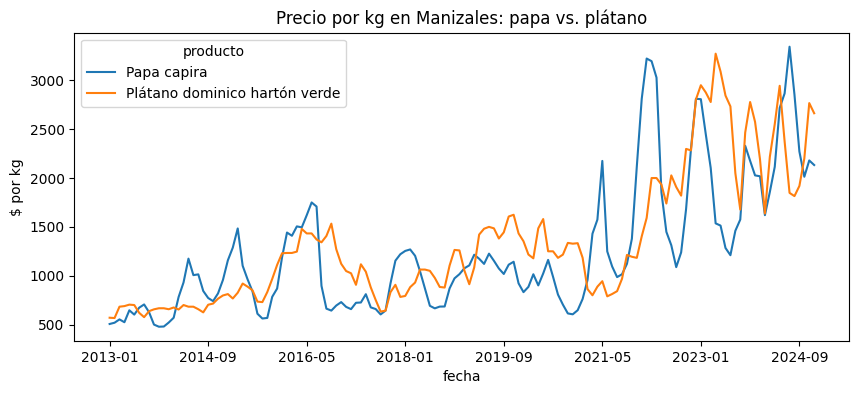

In [ ]:
# ✏️ P3 — ¿Qué subió más en los últimos diez años: la papa o el plátano?
RECETA_P3 = {"Papa capira": 1.0, "Plátano dominico hartón verde": 1.0}

mzl_p3 = filtrar_productos(filtrar_ciudad(df, CIUDAD), RECETA_P3)
precios_p3 = mzl_p3.pivot_table(index="fecha", columns="producto", values="precio_kg", aggfunc="mean")

for inicio in [precios_p3.index[0], "2014-12"]:
    fin = precios_p3.index[-1]
    print(f"\nDe {inicio} a {fin}:")
    for producto in RECETA_P3:
        p0, p1 = precios_p3.loc[inicio, producto], precios_p3.loc[fin, producto]
        print(f"  {producto}: ${p0:,.0f} → ${p1:,.0f}/kg  ({100 * (p1 / p0 - 1):+.0f} %)")

precios_p3.plot(figsize=(10, 4), title="Precio por kg en Manizales: papa vs. plátano")
plt.ylabel("$ por kg")
plt.show()

---
## 4 · Momento 3 — Explicar

🗣️ Media página del equipo: confronten P1 y P2, expliquen cómo decidieron los nombres oficiales y completen la frase: **«Un pipeline es una composición de funciones porque…»**

**Confrontación de predicciones**

- **P1 — costo del sancocho:** apostamos \$62.062 y el costo real en Manizales en diciembre de 2024 fue \$28.634. Nos pasamos unas 2,2 veces, sobre todo por el precio del espinazo (\$36.000/kg estimado contra \$13.500/kg mayorista). Pensamos en precios de tienda y el DANE mide precios de la central de abastos.
- **P2 — qué ingrediente manda:** acertamos: el espinazo aporta \$20.250 de \$28.634, el 71 % de la olla, más que todo lo demás junto. Pero sobreestimamos su peso (calculamos 87 %) por el mismo error de precio de P1. Aunque es solo 1,5 de los 5,8 kg de la receta, su precio por kilo es entre 5 y 10 veces el de los demás ingredientes.
- **P3 — papa o plátano:** apostamos que subía más la papa y subió más el plátano: +234 % contra +123 % de diciembre de 2014 a diciembre de 2024 (+367 % contra +322 % desde enero de 2013). La gráfica muestra que la papa es la más inestable, con los picos más bruscos, pero el plátano fue el que más subió en total: inestabilidad y aumento no son lo mismo.

**Cómo decidimos los nombres oficiales**

Usamos la celda del Ejercicio 2: cambiamos `busca` por una palabra clave de cada ingrediente («espinazo», «yuca», «papa», «mazorca», «plátano»), con `case=False` para no depender de mayúsculas, y luego repetimos la búsqueda restringida a Manizales con la pista del cuaderno. En todo el país aparecen muchas variedades (22 tipos de papa, 4 de yuca y 11 de plátano), pero en Manizales hay muchas menos: espinazo y mazorca tienen un solo nombre («Carne de cerdo, espinazo» y «Chócolo mazorca»); de yuca solo se vende la «Yuca ICA»; de papa hay seis variedades y escogimos la «Papa capira», la de uso común en sancocho; y de plátano verde la única opción en Manizales es «Plátano dominico hartón verde», porque el «Plátano hartón verde» y sus variantes no se registran allí. La búsqueda de «papa» también trajo «Papaya Maradol» y «Carne de cerdo, tocino papada», porque encuentra la palabra en cualquier parte del nombre; esas las descartamos a mano. Para confirmar, verificamos que los cinco nombres de `RECETA` tienen datos en Manizales: cada uno aparece en los 144 meses (enero de 2013 a diciembre de 2024) y en una sola central, Centro Galerías; por eso `filtrar_productos` devolvió exactamente 5 filas.

**Un pipeline es una composición de funciones porque…**

La salida de una función se convierte en la entrada de la siguiente, lo cual permite encadenar varias operaciones para obtener el resultado final.



---
## 🤖 Protocolo de IA

Las reglas de siempre siguen vigentes: intento propio, la IA no es autoridad final y todo uso va en la bitácora individual. Para la cacería estrella pregunten a una IA, sin contexto: *«¿cuánto cuesta hacer un sancocho para seis personas en Colombia?»*. Guarden la respuesta y la fecha. En la sesión 2 la compararán con el índice construido sobre datos oficiales.

**Próxima sesión:** el índice en el tiempo, los picos históricos, el duelo de ciudades, la conmutatividad y la unidad sancocho. Averigüen antes qué ingredientes lleva el plato de su casa.